# RHM sampling complexity under the LS machine -- 2026-11-03

**Question.** How many training grids `P` does the local-score (LS) machine need before the grids it
generates are *both* novel (not in the training set) and fully grammatical, and how does that `P`
scale with the RHM parameters?

**Answer measured here.** `P* = 0.21 |R_L|`, i.e. `P* = Theta(|R_L|) = Theta(v m^((n-1)/(s^2-1)))
= exp(Theta(n))` with `n = s^(2L)` sites. Established by collapsing 30 success peaks onto the
*exact* enumerated grammar size, not by a derivation.

**This supersedes the 2026-11-02 result** in `rhm_sampling_complexity_results.ipynb`. That one
reached the same asymptotic answer through a ceiling `C(k) = f0^U` which assumed a window
straddling a block boundary constrains nothing. hshunt flagged the assumption, exact enumeration
disproved it, and the ceiling argument is withdrawn. The comparison against it is at the bottom.

## Configuration, seeds, provenance

| | |
|---|---|
| repo / commit | `convolutional_diffusion` @ `89d3d82` (+ this notebook) |
| RHM | 2D, `s = 2`, `L in {2, 3}`, `v in {2,3,4,6,8}`, `m in {2..6}` |
| rule seeds | `1000 + rs`, `rs in {0, 1, 2}` (3 independent grammars per `(v, m, L)`) |
| cell seed | `7_000_000 + 1000*rs + P`; generator seed `cell + 9973` |
| window | `k = U1 = 2 s^(L-1) - 1` (k=3 at L=2, k=7 at L=3); k=5 as the control |
| LS machine | `block_align=1` (one pooled, translation-invariant table), `pad_mode='outside'`, `alpha_smooth=1e-3` |
| diffusion | absorbing-state, 64 steps, **one site revealed per step** (exact ancestral sampling) |
| n_gen | 1024 at L=3, 512-8192 at L=2 |
| Slurm jobs | 50903850 (exact `N_k`, `|R_L|`), 50930718 (L=3 k=7 scan), 50935971 (L=3 peak hunt + k=5 control), 50976107 (deck) |
| results dir | `results/rhm_sampling/2026-11-03/` |

In [1]:
import glob, json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
D = ROOT / 'results/rhm_sampling/2026-11-03'

U1 = lambda s, L: 2 * s ** (L - 1) - 1      # window that just reaches the root

RL, NK = {}, {}
for f in glob.glob(str(D / 'nk_exact_L*.json')):
    for r in json.load(open(f)):
        RL[(r['v'], r['m'], r['s'], r['L'], r['rule_seed'])] = r['R_L']
        NK[(r['v'], r['m'], r['s'], r['L'], r['rule_seed'], r['k'])] = r['N_k']

rows = []
for pat in ('L3peak_v*.json', 'L3k7_v*_m*.json', 'P_v*_m*.json'):
    for f in glob.glob(str(D / pat)):
        rows += [r for r in json.load(open(f)) if 'success' in r]

peaks = json.load(open(D / 'peak_summary.json'))
br = [r for r in peaks if r['bracketed']]
print(f'{len(rows)} evaluated cells, {len(peaks)} U=1 curves, {len(br)} with an interior peak')

2421 evaluated cells, 33 U=1 curves, 30 with an interior peak


## 1. Metrics table: where every U=1 success curve peaks

One row per `(v, m, L, rule seed)`. `P*` is the log-P parabola through the top three points;
`bracketed = False` means the argmax sat at an endpoint, so `P*` there is a bound, not a value,
and those rows are excluded from every statistic below.

In [2]:
hdr = f"{'v':>2} {'m':>2} {'L':>2} {'rs':>3} {'k':>3} {'|R_L|':>9} {'P*':>10} {'P*/|R_L|':>9} "\
      f"{'succ':>6} {'gram':>6} {'novel':>6}  bracketed"
print(hdr); print('-' * len(hdr))
for r in sorted(peaks, key=lambda r: (r['L'], r['v'], r['m'], r['rule_seed'])):
    print(f"{r['v']:>2} {r['m']:>2} {r['L']:>2} {r['rule_seed']:>3} {r['k']:>3} "
          f"{r['R_L']:>9d} {r['P_star']:>10.4g} {r['ratio']:>9.3f} "
          f"{r['succ_max']:>6.3f} {r['gram_at']:>6.3f} {r['novel_at']:>6.3f}  "
          f"{'yes' if r['bracketed'] else 'NO (bound)'}")

 v  m  L  rs   k     |R_L|         P*  P*/|R_L|   succ   gram  novel  bracketed
-------------------------------------------------------------------------------
 2  3  2   0   3       486      41.02     0.084  0.126  0.159  0.966  yes
 2  3  2   1   3       321      20.77     0.065  0.166  0.213  0.954  yes
 2  3  2   2   3       205         10     0.049  0.209  0.263  0.946  NO (bound)
 3  3  2   0   3       729      77.77     0.107  0.024  0.040  0.984  yes
 3  3  2   1   3       474      49.49     0.104  0.028  0.071  0.958  yes
 3  3  2   2   3       612      267.3     0.437  0.068  0.127  0.940  yes
 4  2  2   0   3       128      98.27     0.768  0.004  0.024  0.980  yes
 4  2  2   1   3       128      46.45     0.363  0.017  0.059  0.958  yes
 4  2  2   2   3       128         10     0.078  0.009  0.036  0.972  NO (bound)
 4  3  2   0   3       972      184.2     0.190  0.010  0.022  0.988  yes
 4  3  2   1   3       972      322.7     0.332  0.014  0.030  0.983  yes
 4  3  2   2

In [3]:
R = np.array([r['R_L'] for r in br], float)
P = np.array([r['P_star'] for r in br], float)
ratio = P / R
b, loga = np.polyfit(np.log(R), np.log(P), 1)
resid = np.log(P) - (b * np.log(R) + loga)
sb = np.sqrt((resid ** 2).sum() / (len(R) - 2) / ((np.log(R) - np.log(R).mean()) ** 2).sum())
geo = float(np.exp(np.mean(np.log(ratio))))

print(f'n = {len(br)} bracketed peaks, L in {sorted({r["L"] for r in br})}')
print(f'  |R_L|     {R.min():>12,.0f} - {R.max():>12,.0f}   ({R.max()/R.min():>9,.0f}x)')
print(f'  P*        {P.min():>12,.0f} - {P.max():>12,.0f}   ({P.max()/P.min():>9,.0f}x)')
print(f'  P*/|R_L|  {ratio.min():>12.3f} - {ratio.max():>12.3f}   ({ratio.max()/ratio.min():>9.1f}x)')
print(f'  median {np.median(ratio):.3f}, geometric mean {geo:.3f}, geo-sd '
      f'{np.exp(np.std(np.log(ratio))):.2f}x')
print(f'\nfree power law   P* ~ |R_L|^{b:.3f} +- {sb:.3f}   '
      f'(exponent 1 is {abs(1-b)/sb:.1f} sd away)')
print(f'residual sd about the free fit     {np.exp(np.std(resid)):.2f}x')
con = np.exp(np.mean(np.log(P) - np.log(R)))
print(f'constrained b=1  P* = {con:.3f} |R_L|   residual sd '
      f'{np.exp(np.std(np.log(P) - np.log(con * R))):.2f}x  (no worse)')
for L in sorted({r['L'] for r in br}):
    sub = np.array([r['ratio'] for r in br if r['L'] == L])
    print(f'  L={L}: n={len(sub)}, median P*/|R_L| = {np.median(sub):.3f}')

n = 30 bracketed peaks, L in [2, 3]
  |R_L|              128 -    6,291,456   (   49,152x)
  P*                  21 -    1,326,334   (   63,851x)
  P*/|R_L|         0.065 -        0.768   (     11.9x)
  median 0.197, geometric mean 0.212, geo-sd 1.95x

free power law   P* ~ |R_L|^0.965 +- 0.041   (exponent 1 is 0.8 sd away)
residual sd about the free fit     1.93x
constrained b=1  P* = 0.212 |R_L|   residual sd 1.95x  (no worse)
  L=2: n=25, median P*/|R_L| = 0.193
  L=3: n=5, median P*/|R_L| = 0.207


The two depths agree to 7% in the median while `n` goes 16 -> 64 sites.

**Caveat, stated plainly.** Within L=3 alone the normalized spread (7.9x) is *not* smaller than the
raw `P*` spread (6.6x), because the five L=3 grammars only span 20x in `|R_L|`. The collapse
evidence comes from the combined range: `|R_L|` over 49,152x and `P*` over 63,851x compress to
11.9x in `P*/|R_L|`.

## 2. Key plot: the collapse

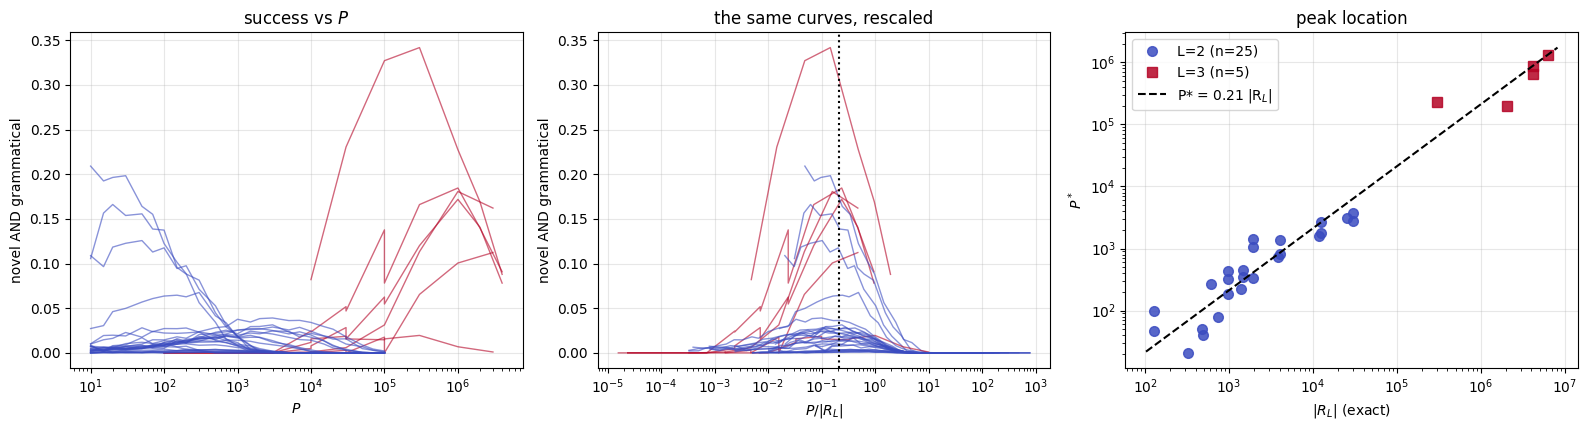

In [4]:
def curves(rows, RL):
    out = {}
    for r in rows:
        if r.get('block_align', 1) != 1 or not isinstance(r.get('k'), int):
            continue
        if r['k'] != U1(r['s'], r['L']):
            continue
        key = (r['v'], r['m'], r['s'], r['L'], r['rule_seed'], r['k'])
        if key[:5] in RL:
            out.setdefault(key, []).append(r)
    return {k: sorted(v, key=lambda r: r['P']) for k, v in out.items()}

cs = curves(rows, RL)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for key, c in sorted(cs.items()):
    col = '#3b4cc0' if key[3] == 2 else '#b40426'
    Pc = np.array([x['P'] for x in c], float)
    Sc = np.array([x['success'] for x in c], float)
    ax[0].plot(Pc, Sc, '-', color=col, lw=1, alpha=.6)
    ax[1].plot(Pc / RL[key[:5]], Sc, '-', color=col, lw=1, alpha=.6)
for L, col, mk in ((2, '#3b4cc0', 'o'), (3, '#b40426', 's')):
    sub = [r for r in br if r['L'] == L]
    ax[2].plot([r['R_L'] for r in sub], [r['P_star'] for r in sub], mk, color=col, ms=7,
               alpha=.85, label=f'L={L} (n={len(sub)})')
xs = np.array([R.min() * .8, R.max() * 1.3])
ax[2].plot(xs, geo * xs, 'k--', lw=1.5, label=f'P* = {geo:.2f} |R$_L$|')
ax[1].axvline(geo, color='k', ls=':', lw=1.5)
ax[2].set_yscale('log'); ax[2].legend()
for a, xl, t in zip(ax, ['$P$', '$P/|R_L|$', '$|R_L|$ (exact)'],
                    ['success vs $P$', 'the same curves, rescaled', 'peak location']):
    a.set_xscale('log'); a.set_xlabel(xl); a.set_title(t); a.grid(alpha=.3)
ax[0].set_ylabel('novel AND grammatical'); ax[1].set_ylabel('novel AND grammatical')
ax[2].set_ylabel('$P^*$')
fig.tight_layout(); plt.show()

Blue is L=2 (16 sites, k=3), red is L=3 (64 sites, k=7); each line is one `(v, m, rule seed)`.
Rules are drawn **with replacement**, so independent seeds at the same `(v, m)` collide differently
and give `|R_L|` differing by up to 20x. That is what makes the middle panel a collapse rather
than a rescaling by a fitted constant.

## 3. Why a peak exists: a window ceiling that saturates, times novelty that decays

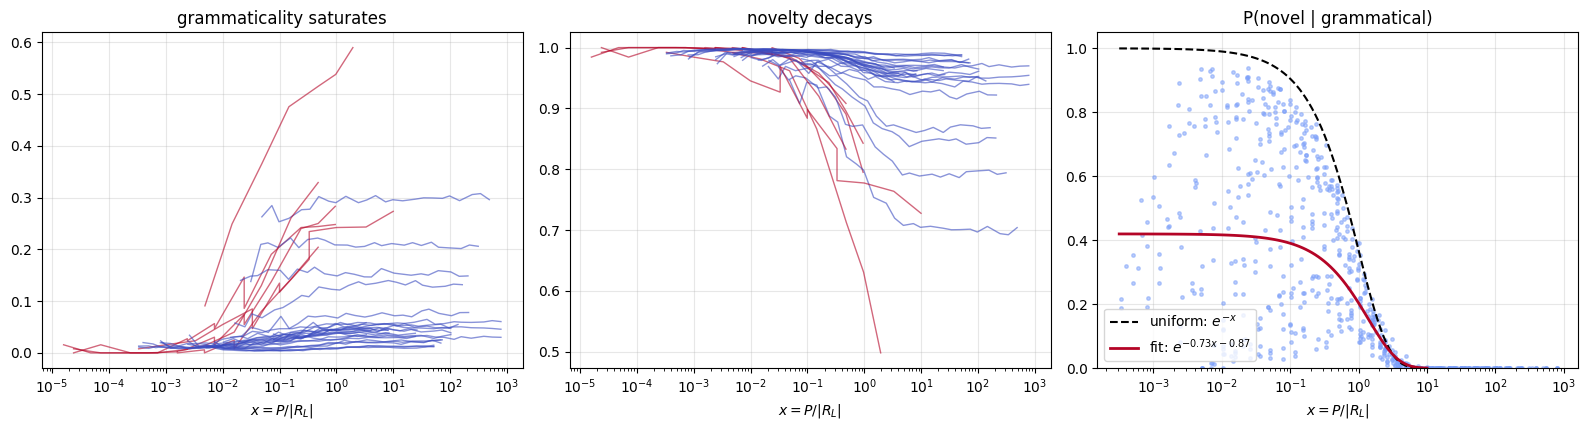

P(novel | grammatical) ~ exp(-0.725 x - 0.868) over 488 cells
uniform sampling from the grammar would give exp(-x): slope 1, intercept 0
intercept 0.87 => only 42% of grammatical outputs are novel as x -> 0


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
gx, gy = [], []
for key, c in sorted(cs.items()):
    col = '#3b4cc0' if key[3] == 2 else '#b40426'
    x = np.array([r['P'] for r in c], float) / RL[key[:5]]
    ax[0].plot(x, [r['grammatical'] for r in c], '-', color=col, lw=1, alpha=.6)
    ax[1].plot(x, [r['novel'] for r in c], '-', color=col, lw=1, alpha=.6)
    for r, xi in zip(c, x):
        if r['grammatical'] * r['n_samples'] >= 8:
            gx.append(xi); gy.append(r['success'] / r['grammatical'])
gx, gy = np.array(gx), np.array(gy)
ok = (gy > .02) & (gy < .999)
sl, ic = np.polyfit(gx[ok], -np.log(gy[ok]), 1)
xs = np.logspace(-3.5, 1, 100)
ax[2].plot(gx, gy, '.', color='#7b9ff9', ms=5, alpha=.5)
ax[2].plot(xs, np.exp(-xs), 'k--', lw=1.5, label='uniform: $e^{-x}$')
ax[2].plot(xs, np.exp(-(sl * xs + ic)), '-', color='#b40426', lw=2,
           label=f'fit: $e^{{-{sl:.2f}x-{ic:.2f}}}$')
ax[2].legend(loc='lower left'); ax[2].set_ylim(0, 1.05)
for a, t in zip(ax, ['grammaticality saturates', 'novelty decays', 'P(novel | grammatical)']):
    a.set_xscale('log'); a.set_xlabel('$x = P/|R_L|$'); a.set_title(t); a.grid(alpha=.3)
fig.tight_layout(); plt.show()

print(f'P(novel | grammatical) ~ exp(-{sl:.3f} x - {ic:.3f}) over {ok.sum()} cells')
print(f'uniform sampling from the grammar would give exp(-x): slope 1, intercept 0')
print(f'intercept {ic:.2f} => only {100*np.exp(-ic):.0f}% of grammatical outputs are novel as x -> 0')

`success(x) = grammatical(x) * P(novel | grammatical, x)`. The first factor rises with data but
flattens at a ceiling fixed by the window (0.25-0.52 at L=3, k=7, depending on the rule draw); the
second falls. Both are functions of `x = P/|R_L|` alone, so their product peaks at a fixed `x`.

The intercept is the part that is *not* coverage: even as `x -> 0`, only ~42% of grammatical
outputs are novel. When the LS machine gets the grammar right it is disproportionately reproducing
a training grid -- a P-independent memorization drag on top of the `exp(-x)` term, and the reason
peak success is low even at its best.

## 4. Control: below the U=1 window, no amount of data helps

A `k x k` window reaches `k//2`, so it contains the aligned block of side `b` through its centre
only when `k >= 2b - 1`; writing `j* = floor(log_s((k+1)/2))`, reaching the root needs
`k >= 2 s^(L-1) - 1`. At L=3 that is k=7, and k=5 is the control.

In [6]:
sel = [r for r in rows if r['v'] == 2 and r['m'] == 2 and r['L'] == 3
       and r.get('block_align', 1) == 1 and isinstance(r.get('k'), int)]
print(f"{'k':>2} {'rs':>3} {'P':>9} {'gram':>7} {'succ':>7} {'table size':>11}  table vs exact N_k")
print('-' * 70)
for k in (5, 7):
    for rs in (0, 1, 2):
        for r in sorted([x for x in sel if x['k'] == k and x['rule_seed'] == rs],
                        key=lambda x: x['P']):
            if r['P'] < 10000:
                continue
            nk = NK.get((2, 2, 2, 3, rs, k))
            tag = f"{r['n_distinct_patches']/nk:.3f} of N_{k}={nk:,}" if nk else ''
            print(f"{k:>2} {rs:>3} {r['P']:>9d} {r['grammatical']:>7.3f} {r['success']:>7.3f} "
                  f"{r['n_distinct_patches']:>11,d}  {tag}")
    print()

 k  rs         P    gram    succ  table size  table vs exact N_k
----------------------------------------------------------------------
 5   0     10000   0.002   0.002      66,613  0.723 of N_5=92,080
 5   0     10000   0.000   0.000      66,613  0.723 of N_5=92,080
 5   0     30000   0.000   0.000      84,516  0.918 of N_5=92,080
 5   0    100000   0.005   0.004      91,645  0.995 of N_5=92,080
 5   0    100000   0.008   0.008      91,645  0.995 of N_5=92,080
 5   0   1000000   0.004   0.004      92,080  1.000 of N_5=92,080
 5   0   4000000   0.003   0.001      92,080  1.000 of N_5=92,080
 5   1     10000   0.003   0.003      82,342  0.670 of N_5=122,948
 5   1     10000   0.000   0.000      82,342  0.670 of N_5=122,948
 5   1     30000   0.000   0.000     111,739  0.909 of N_5=122,948
 5   1    100000   0.002   0.002     122,492  0.996 of N_5=122,948
 5   1    100000   0.000   0.000     122,492  0.996 of N_5=122,948
 5   1   1000000   0.004   0.003     122,948  1.000 of N_5=122,948


This is the decisive control. At k=5 the patch table **saturates at exactly `N_5`** -- the exact
enumeration over the whole grammar, so the table is provably complete, it has seen every window the
grammar can produce -- and grammaticality never exceeds 0.7% anywhere on the ladder (0.3% and
0.7% at `P = 4e6` for the two seeds), with no trend over 400x in data. Rows that repeat a `P`
are independent repeat evaluations of the same table from two jobs (50930718 and 50935971);
the scatter between them is the 1/n_gen noise floor.
On the same grammars k=7 reaches 0.25-0.52. L=4 at k<=5 corroborates: the root never parses and
`level_parse_fraction[2]` only reaches 0.05-0.12.

So below the U=1 window the binding constraint is the window, not the data, and every
sampling-complexity curve above is therefore taken at `k = U1`.

## 5. Comparison with the previous best on the same eval

Same eval throughout: fraction of generated grids that are novel **and** fully grammatical, exact
bottom-up parse, `block_align=1`, one site revealed per step.

| | 2026-11-02 (`rhm_sampling_complexity_results.ipynb`) | 2026-11-03 (this notebook) |
|---|---|---|
| claimed law | `P* = exp(Theta(n))` | `P* = 0.21 |R_L| = exp(Theta(n))` |
| route | derived from a ceiling `C(k) = f0^U` | measured: 30 peaks collapsed onto exact `|R_L|` |
| status of the route | **retracted** -- the ceiling assumed a straddling window constrains nothing, which exact enumeration disproved | standing |
| best L=3 success observed | 0.000 (no k=7 run had been done; all L=3 runs were k<=5) | **0.342** (v2m2 rs2, P=2e5) |
| L=3 grammaticality | 0.000 at every P | 0.25-0.52 at k=7 |
| evidence span | L=2 only, plus a derivation | `|R_L|` over 49,152x, `P*` over 63,851x, two depths |

The asymptotic answer did not move. What changed is that it is now a measurement, that the
window condition `k >= 2 s^(L-1) - 1` is identified and controlled for, and that L=3 is no longer
a flat zero -- the earlier L=3 runs were all below the U=1 window and could not have succeeded at
any `P`.

## 6. Honest limits

- **Peak success is low.** Median 0.022 over the 30 curves, best 0.342. The law locates the
  optimum; it does not claim the optimum is good. The peak also decays with `v` and `m`.
- **Two depths.** L=2 (16 sites) and L=3 (64 sites). L=4 needs k=15, whose patch table is out of
  reach, so `exp(Theta(n))` rests on those two depths plus the exact `N_k = Theta(|R_L|)` counts.
- **The constant is not sharp.** Exponent `0.965 +- 0.040` (consistent with 1) but residual
  scatter 1.95x, so `0.21` should be read as "a fixed fraction of order 0.2", not a precise value.
- **One L=3 curve is unbracketed** (v3m2 rs0: success still climbing at P=3e6, so `x* >= 0.477`);
  it is excluded from the statistics rather than counted as a peak.
- **Straddling** (hshunt's question) is measured separately: `R_1 = lvl[1]/lvl[2]^4` has median
  0.4 at k=3, 1.7 at k=5, 2.1 at k=7, so once the window spans a block boundary sibling subtrees
  become positively correlated. That statistic conflates window size with straddling; the
  block-aligned-only control that would separate them does not exist yet (`block_align=s` is not
  it -- a per-phase table gives the machine *more* information, not less).